# Preparación de datos -  AIRBNB

1. Integración de los datos
2. Eliminar variables irrelevantes y redundantes
3. Descripción estadística de los datos
4. Limpieza de datos atípicos-errores
5. Limpieza de datos nulos
6. Análisis de correlaciones para redundancias entre todas las variables
7. Análisis de correlaciones para irrelevancias respecto a la objetivo
8. Guardar los datos preparados (`data/Airbnb_NYC_2019_limpio.csv`), que son la entrada de la minería de características y del modelado

*Nota: el balanceo y las transformaciones (ingeniería de características) no se incluyen en este notebook; se realizan en la etapa siguiente.*

In [1]:
#Importamos librerías básicas
import pandas as pd # manipulacion dataframes
import numpy as np  # matrices y vectores
import matplotlib.pyplot as plt #gráfica

# 1. Integración de Datos

In [2]:
import os

# Ruta del dataset original: carpeta data/ del repositorio o carpeta actual (Colab)
CARPETA_DATOS = next((d for d in ['../data', 'data'] if os.path.exists(os.path.join(d, 'AB_NYC_2019.csv'))), '.')

data = pd.read_csv(os.path.join(CARPETA_DATOS, 'AB_NYC_2019.csv'))
data.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [4]:
#Variables categoricas
for col in data.columns:
    if data[col].dtype == 'object':
        data[col] = data[col].astype('category')

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   id                              48895 non-null  int64   
 1   name                            48879 non-null  category
 2   host_id                         48895 non-null  int64   
 3   host_name                       48874 non-null  category
 4   neighbourhood_group             48895 non-null  category
 5   neighbourhood                   48895 non-null  category
 6   latitude                        48895 non-null  float64 
 7   longitude                       48895 non-null  float64 
 8   room_type                       48895 non-null  category
 9   price                           48895 non-null  int64   
 10  minimum_nights                  48895 non-null  int64   
 11  number_of_reviews               48895 non-null  int64   
 12  last_review       

In [5]:
#Revisamos si tenemos ID repetidos
ids = data['id'].value_counts()
ids[ids > 1]

#Sólo dejamos el id mas reciente
data.drop_duplicates(subset=['id'], keep='last', inplace=True)

#Verificamos de nuevo si tenemos ID repetidos
ids = data['id'].value_counts()
ids[ids > 1]

Series([], Name: count, dtype: int64)

# 2. Eliminar variables irrelevantes y redundantes
* Irrelevantes: cedulas, ids, nombres de personas, telefonos, direcciones, códigos.
* Redundantes: validación por fórmula matemática que están repetidas

In [6]:
# Irrelevantes: identificadores y nombre del anfitrión (id, host_id, host_name)
data = data.drop(['id', 'host_id', 'host_name'], axis=1)  # axis=1 indica que son columnas
data.head()

,name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,Clean & quiet apt home by the park,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,Skylit Midtown Castle,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,THE VILLAGE OF HARLEM....NEW YORK !,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,Cozy Entire Floor of Brownstone,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,Entire Apt: Spacious Studio/Loft by central park,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


Se eliminan los identificadores (`id`, `host_id`) y el nombre de la persona anfitriona (`host_name`): no describen el alojamiento y no sirven para predecir el precio.

Se **conservan** dos variables que no se pueden usar tal como vienen, pero que contienen información sobre el precio y se transforman en la etapa de ingeniería de características (notebook `04_mineria_caracteristicas`):
* **`name`**: no es el nombre de una persona, sino el **título del anuncio**. Palabras como *luxury*, *penthouse* o *cozy* indican el segmento del alojamiento.
* **`neighbourhood`** (221 micro-barrios): no es redundante con las coordenadas, porque el precio cambia entre barrios vecinos. Su alta cardinalidad impide crear dummies, así que se codificará con *Target Encoding*.

Como son texto y una categórica de alta cardinalidad, quedan fuera de los análisis de correlación de este notebook.

# 3. Descripción estadística

**Variables numéricas**

In [7]:
data.describe()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


array([[<Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'price'}>],
       [<Axes: title={'center': 'minimum_nights'}>,
        <Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>, <Axes: >]],
      dtype=object)

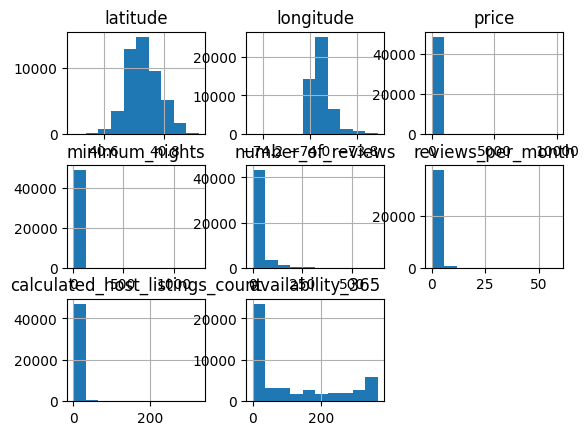

In [8]:
#Histogramas
data.hist()

<Axes: >

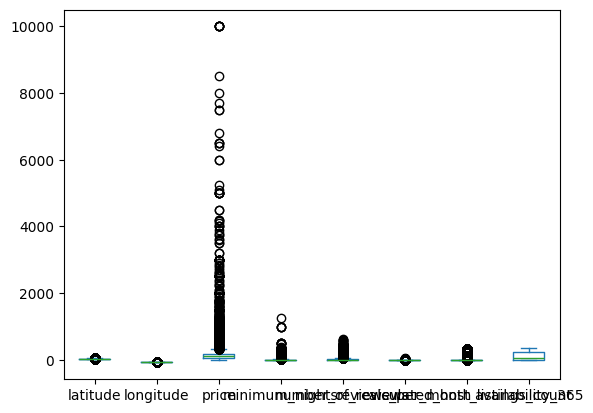

In [9]:
data.plot.box()

<Axes: >

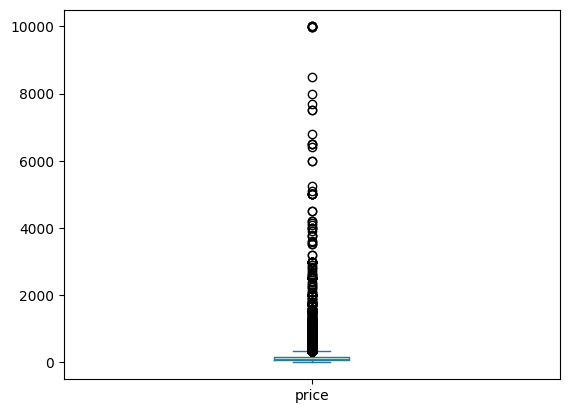

In [10]:
data['price'].plot.box()


<Axes: >

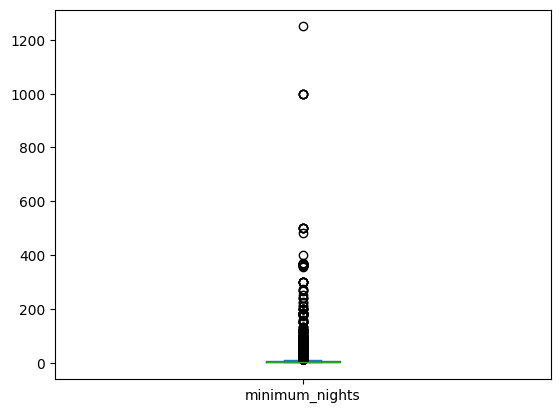

In [11]:
data['minimum_nights'].plot.box()

**Variables categóricas** (value_counts())

<Axes: xlabel='neighbourhood_group'>

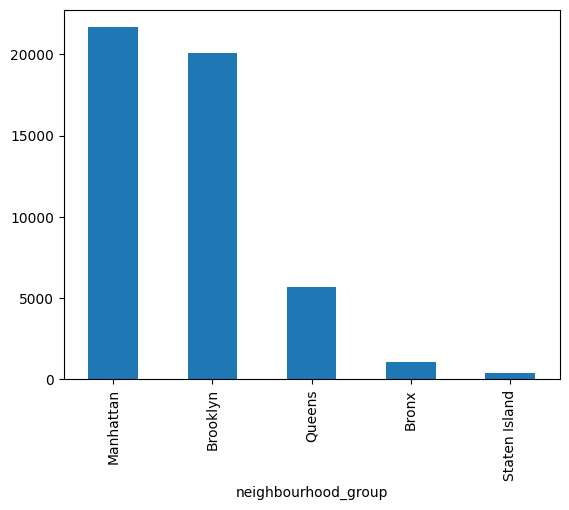

In [12]:
data['neighbourhood_group'].value_counts().plot(kind='bar')

<Axes: ylabel='room_type'>

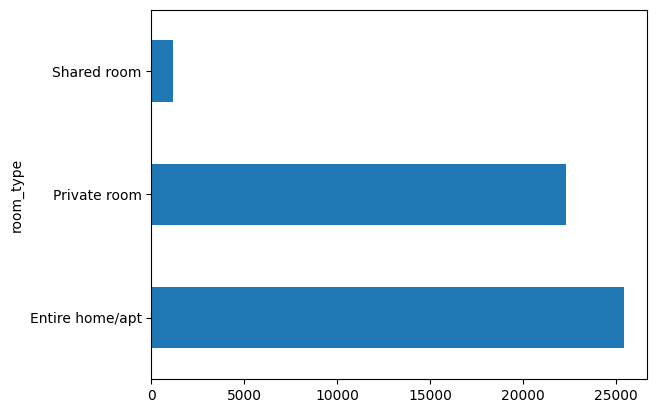

In [13]:
data['room_type'].value_counts().plot(kind='barh')

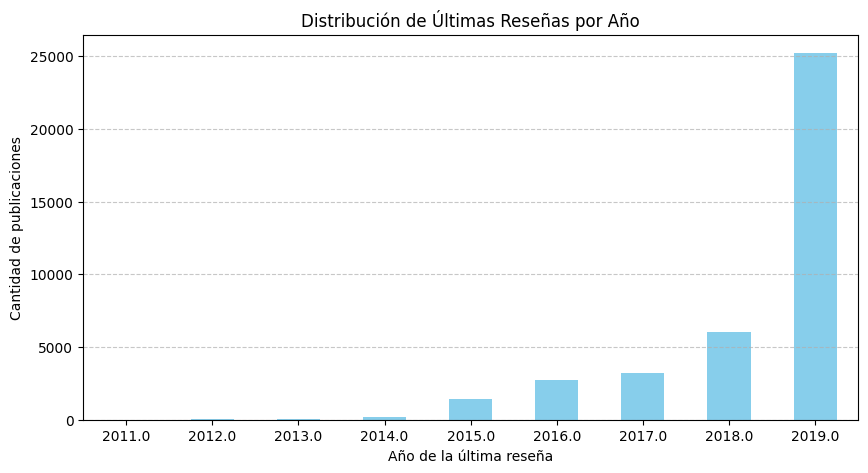

In [14]:
# Convertimos la columna a tipo datetime para poder extraer componentes temporales
data['last_review'] = pd.to_datetime(data['last_review'])

# Extraemos el año de la última reseña y graficamos su frecuencia de manera legible
plt.figure(figsize=(10, 5))
data['last_review'].dt.year.value_counts().sort_index().plot(kind='bar', color='skyblue')
plt.title('Distribución de Últimas Reseñas por Año')
plt.xlabel('Año de la última reseña')
plt.ylabel('Cantidad de publicaciones')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Gráficas de las relaciones entre variables**

array([[<Axes: xlabel='latitude', ylabel='latitude'>,
        <Axes: xlabel='longitude', ylabel='latitude'>,
        <Axes: xlabel='price', ylabel='latitude'>,
        <Axes: xlabel='minimum_nights', ylabel='latitude'>,
        <Axes: xlabel='number_of_reviews', ylabel='latitude'>,
        <Axes: xlabel='reviews_per_month', ylabel='latitude'>,
        <Axes: xlabel='calculated_host_listings_count', ylabel='latitude'>,
        <Axes: xlabel='availability_365', ylabel='latitude'>],
       [<Axes: xlabel='latitude', ylabel='longitude'>,
        <Axes: xlabel='longitude', ylabel='longitude'>,
        <Axes: xlabel='price', ylabel='longitude'>,
        <Axes: xlabel='minimum_nights', ylabel='longitude'>,
        <Axes: xlabel='number_of_reviews', ylabel='longitude'>,
        <Axes: xlabel='reviews_per_month', ylabel='longitude'>,
        <Axes: xlabel='calculated_host_listings_count', ylabel='longitude'>,
        <Axes: xlabel='availability_365', ylabel='longitude'>],
       [<Axes: xlabel=

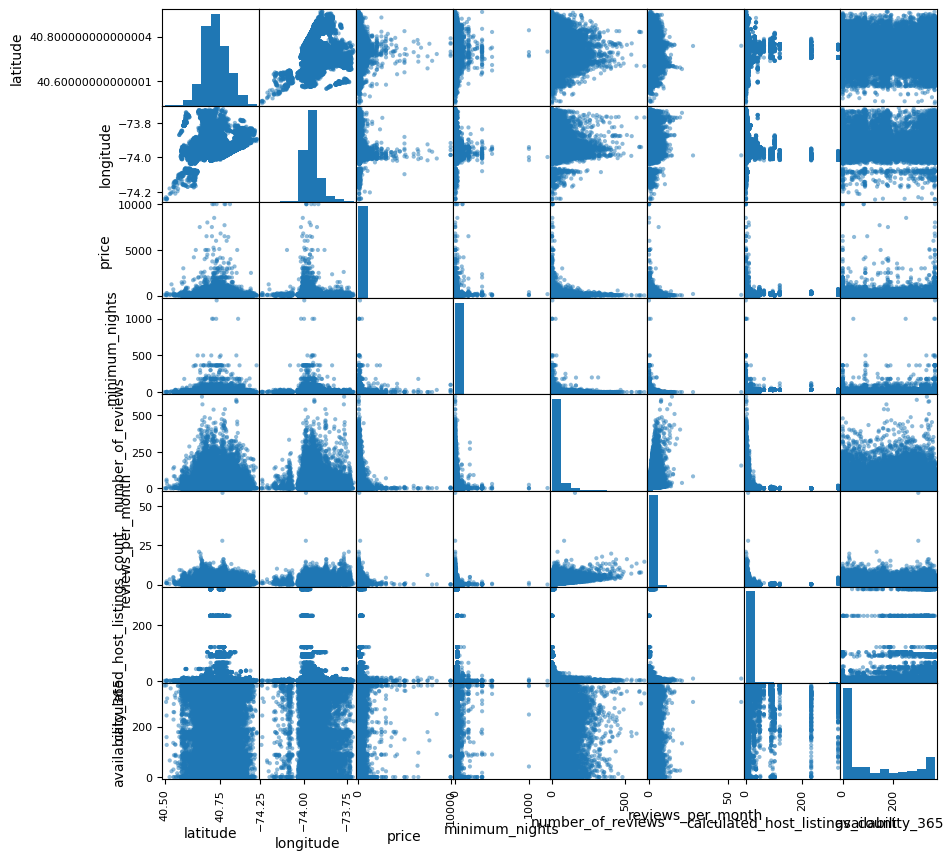

In [15]:
# Gráficas para identificar relaciones entre las variables
pd.plotting.scatter_matrix(data, figsize=(10,10))

**Perfilado de datos**

In [16]:
!pip install ydata-profiling
from ydata_profiling import ProfileReport
profile_data=ProfileReport(data, minimal=True) # minimal=True
profile_data

/tmp/ipykernel_361/2547657967.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

  8%|▊         | 1/13 [00:00<00:01,  6.08it/s]

100%|██████████| 13/13 [00:00<00:00, 77.70it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [17]:
#Guardamos en html el perfilado de datos
ruta_perfil = '../docs/output.html' if os.path.exists('../docs') else 'output.html'
profile_data.to_file(output_file=ruta_perfil)

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

# 4. Limpieza de datos atípicos-errores
- Sólo se limpian errores

Se ha decidido conservar los valores atípicos (outliers) detectados en la variable objetivo price y en otras características estructurales del conjunto de datos, en lugar de eliminarlos o imputarlos. Esto se debe a que dichos extremos tales como propiedades con tarifas por noche excepcionalmente elevadas— corresponden a fenómenos de mercado reales y legítimos (por ejemplo, alojamientos de lujo o villas exclusivas) y no a errores de captura o ruido instrumental. Eliminar o alterar estos registros mediante imputaciones artificiales restaría valor predictivo al modelo, distorsionando la variabilidad natural del mercado de alquileres en Nueva York y privando al algoritmo de información clave sobre el segmento de alta gama.

Sí se eliminan los registros que corresponden a **errores**:
* `price = 0`: un alojamiento no puede costar 0 dólares por noche.
* `minimum_nights > 365`: un mínimo de estadía superior a un año (con valores de hasta 1250 noches) no es coherente con un alquiler por noches y se considera un error de captura.

In [18]:
# Guardamos la cantidad inicial de registros para comparar
registros_iniciales = len(data)

# Aplicamos las reglas de calidad de datos (sólo errores)
data = data[data['price'] > 0]
data = data[(data['minimum_nights'] > 0) & (data['minimum_nights'] <= 365)]

# Mostramos los resultados del filtrado
registros_finales = len(data)
print(f"Registros iniciales: {registros_iniciales}")
print(f"Registros después de la limpieza: {registros_finales}")
print(f"Registros eliminados: {registros_iniciales - registros_finales}")

data.head()

Registros iniciales: 48895
Registros después de la limpieza: 48870
Registros eliminados: 25


,name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,Clean & quiet apt home by the park,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,Skylit Midtown Castle,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,THE VILLAGE OF HARLEM....NEW YORK !,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaT,NaN,1,365
3,Cozy Entire Floor of Brownstone,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,Entire Apt: Spacious Studio/Loft by central park,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


**5. Limpieza de datos nulos: Imputación**

Estrategia:
* Eliminar registros con mas de 15% de nulos
* Eliminar columnas con mas de 15%-20% de nulos
* Imputar por media, moda, mediana, vecinos cercanos. No se puede imputar más allá del 15% de los datos.
* Para casos especiales se crea modelo predictivo

In [19]:
# Calculamos la cantidad y el porcentaje de valores nulos por columna
valores_nulos = data.isnull().sum()
porcentaje_nulos = (valores_nulos / len(data)) * 100

# Creamos un DataFrame para mostrar los resultados de manera ordenada
resumen_nulos = pd.DataFrame({
    'Valores Nulos': valores_nulos,
    'Porcentaje (%)': porcentaje_nulos
})

# Ordenamos de mayor a menor según el porcentaje de nulos
resumen_nulos = resumen_nulos.sort_values(by='Porcentaje (%)', ascending=False)

display(resumen_nulos)

,Valores Nulos,Porcentaje (%)
reviews_per_month,10043,20.550440
last_review,10043,20.550440
name,15,0.030694
neighbourhood_group,0,0.000000
neighbourhood,0,0.000000
longitude,0,0.000000
latitude,0,0.000000
room_type,0,0.000000
price,0,0.000000
number_of_reviews,0,0.000000


**Tratamiento de los nulos**

* `reviews_per_month` y `last_review` tienen el mismo número de nulos (20.6 %). Se comprueba que son nulos **estructurales**: aparecen exactamente en los alojamientos con `number_of_reviews = 0`, es decir, que nunca han recibido reseñas.
* `reviews_per_month`: si no hay reseñas, el número de reseñas por mes es 0. Por lo tanto, no se trata de un dato perdido y se imputa con 0 (no aplica el límite del 15 %, porque el valor se conoce con certeza).
* `last_review`: es una fecha y no existe un valor con sentido para un alojamiento sin reseñas, por lo que la columna se elimina (supera el 15 %-20 % de nulos).
* `name`: tiene muy pocos nulos (anuncios sin título, menos del 0.1 %). Se imputan con un texto vacío, que equivale a un título sin palabras clave.


In [20]:
# Verificamos que los nulos de reviews_per_month coinciden con los alojamientos sin reseñas
print("¿Nulos de reviews_per_month = alojamientos con 0 reseñas?:",
      (data['reviews_per_month'].isna() == (data['number_of_reviews'] == 0)).all())

# Imputamos con 0 (sin reseñas -> 0 reseñas por mes) y eliminamos last_review
data['reviews_per_month'] = data['reviews_per_month'].fillna(0)
data = data.drop(columns=['last_review'])

# Anuncios sin título: texto vacío (título sin palabras clave)
data['name'] = data['name'].astype(str).replace('nan', '').where(data['name'].notna(), '')

# Verificamos que ya no existan valores nulos en el dataset
print("\nValores nulos restantes por columna:")
print(data.isnull().sum())

# Visualizamos las dimensiones finales del dataset
print(f"\nDimensiones del dataset: {data.shape}")

¿Nulos de reviews_per_month = alojamientos con 0 reseñas?: True

Valores nulos restantes por columna:
name                              0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

Dimensiones del dataset: (48870, 12)


In [21]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48870 entries, 0 to 48894
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   name                            48870 non-null  object  
 1   neighbourhood_group             48870 non-null  category
 2   neighbourhood                   48870 non-null  category
 3   latitude                        48870 non-null  float64 
 4   longitude                       48870 non-null  float64 
 5   room_type                       48870 non-null  category
 6   price                           48870 non-null  int64   
 7   minimum_nights                  48870 non-null  int64   
 8   number_of_reviews               48870 non-null  int64   
 9   reviews_per_month               48870 non-null  float64 
 10  calculated_host_listings_count  48870 non-null  int64   
 11  availability_365                48870 non-null  int64   
dtypes: category(3), float64

# 6. Correlaciones para redundancias

In [22]:
# Todas las variables deben ser numéricas para calcular las correlaciones
# Se crean dummies para las variables categóricas

# name (texto libre) y neighbourhood (221 categorías) se excluyen: se transforman en la ingeniería de características
data_num = pd.get_dummies(data.drop(columns=['name', 'neighbourhood']), drop_first=False, dtype=int)
data_num.head()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,0,1,0,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,0,1,0,0,1,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,0,0,1,0,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,0,1,0,0,0,1,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,0,1,0,0,1,0,0


In [23]:
#Correlaciones
correlaciones=data_num.corr()
correlaciones

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
latitude,1.000000,0.084824,0.033895,0.029893,-0.015356,-0.018717,0.019521,-0.010876,0.330608,-0.672901,0.590667,0.017081,-0.190937,-0.005925,0.004525,0.004647
longitude,0.084824,1.000000,-0.149932,-0.073948,0.058978,0.138399,-0.114735,0.082869,0.221255,0.017554,-0.433452,0.622953,-0.291873,-0.192056,0.183555,0.029742
price,0.033895,-0.149932,1.000000,0.053605,-0.047931,-0.050540,0.057461,0.081876,-0.040988,-0.098459,0.163874,-0.080291,-0.013855,0.255788,-0.240222,-0.053515
minimum_nights,0.029893,-0.073948,0.053605,1.000000,-0.095235,-0.149114,0.161516,0.164525,-0.020903,-0.048024,0.081609,-0.040273,-0.010710,0.090733,-0.087355,-0.011962
number_of_reviews,-0.015356,0.058978,-0.047931,-0.095235,1.000000,0.589283,-0.072409,0.172223,0.009156,0.017359,-0.045743,0.035980,0.015085,-0.009958,0.017071,-0.023207
reviews_per_month,-0.018717,0.138399,-0.050540,-0.149114,0.589283,1.000000,-0.047356,0.163978,0.036271,-0.021603,-0.063646,0.107999,0.026645,-0.029398,0.029941,-0.001488
calculated_host_listings_count,0.019521,-0.114735,0.057461,0.161516,-0.072409,-0.047356,1.000000,0.225867,-0.022519,-0.123261,0.152871,-0.033889,-0.012844,0.112234,-0.108991,-0.011729
availability_365,-0.010876,0.082869,0.081876,0.164525,0.172223,0.163978,0.225867,1.000000,0.060907,-0.079795,-0.005414,0.087202,0.057946,-0.006851,-0.010815,0.057947
neighbourhood_group_Bronx,0.330608,0.221255,-0.040988,-0.020903,0.009156,0.036271,-0.022519,0.060907,1.000000,-0.126188,-0.134725,-0.054686,-0.013246,-0.051998,0.042642,0.031165
neighbourhood_group_Brooklyn,-0.672901,0.017554,-0.098459,-0.048024,0.017359,-0.021603,-0.123261,-0.079795,-0.126188,1.000000,-0.745218,-0.302493,-0.073269,-0.073615,0.079230,-0.017673


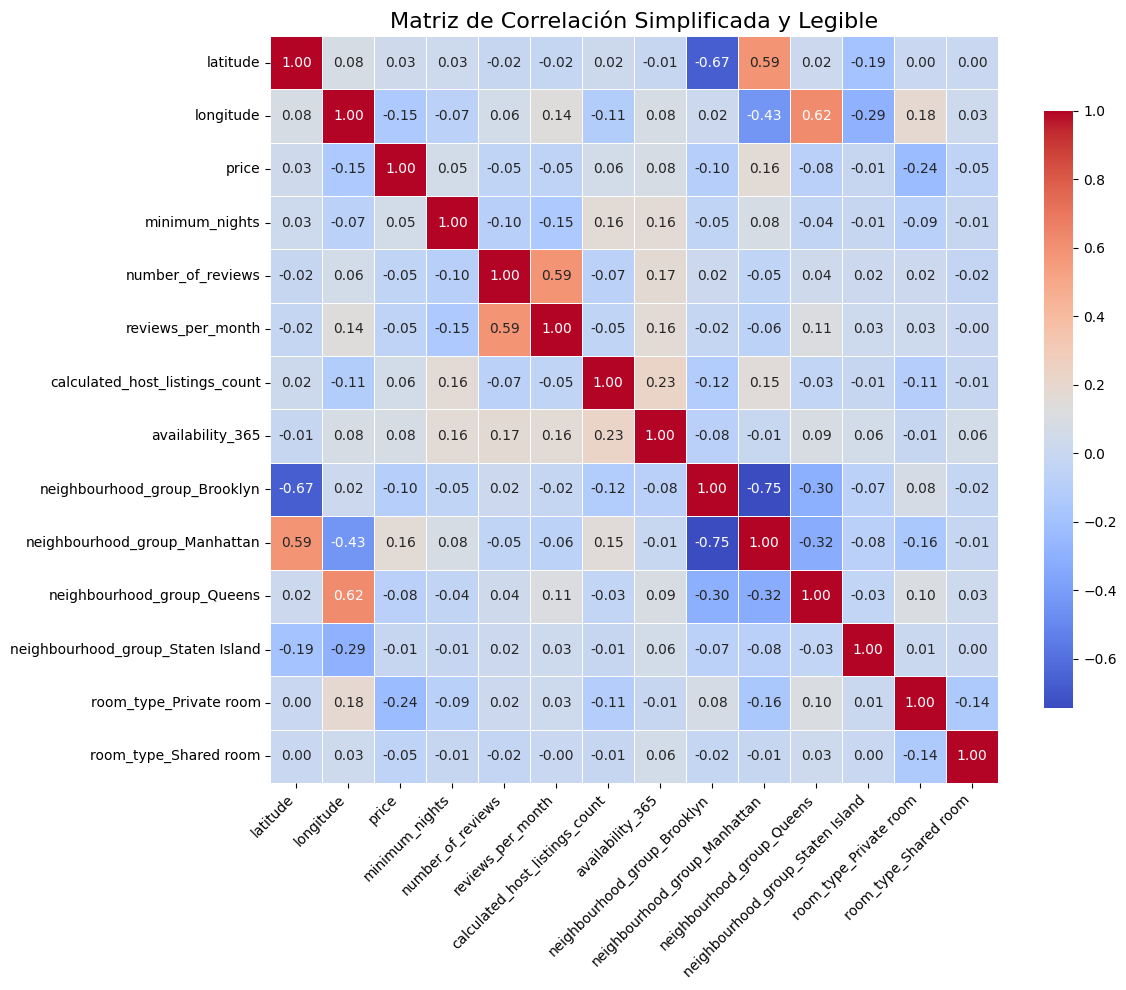

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Seleccionamos las columnas numéricas e incluimos las de baja cardinalidad convertidas a dummies
columnas_interes = ['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
data_reducida = pd.get_dummies(data[columnas_interes + ['neighbourhood_group', 'room_type']], drop_first=True, dtype=int)

# Calculamos la nueva matriz de correlación
corr_reducida = data_reducida.corr()

# Graficamos un mapa de calor legible y limpio
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_reducida,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title('Matriz de Correlación Simplificada y Legible', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 7. Correlaciones para irrelevancia con la variable objetivo

Se buscan correlaciones con la variable objetivo muy bajas (0.0-0.05 ) ->ultima fila

In [25]:
#Correlaciones con la variable de objetivo
cor_variable_obj=correlaciones.loc['price']
cor_variable_obj

latitude                             0.033895
longitude                           -0.149932
price                                1.000000
minimum_nights                       0.053605
number_of_reviews                   -0.047931
reviews_per_month                   -0.050540
calculated_host_listings_count       0.057461
availability_365                     0.081876
neighbourhood_group_Bronx           -0.040988
neighbourhood_group_Brooklyn        -0.098459
neighbourhood_group_Manhattan        0.163874
neighbourhood_group_Queens          -0.080291
neighbourhood_group_Staten Island   -0.013855
room_type_Entire home/apt            0.255788
room_type_Private room              -0.240222
room_type_Shared room               -0.053515
Name: price, dtype: float64

Para variables con 3 o más categorias se calcula promedio ponderado de las dummies que corresponden a la misma variable

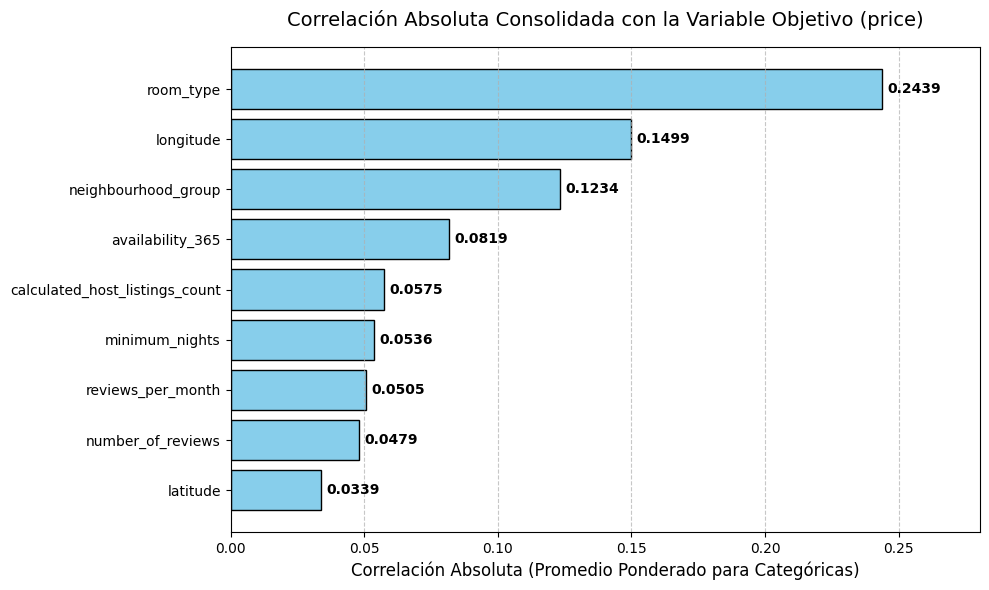

In [26]:
# 1. Identificamos variables numéricas directas
vars_numericas = ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
corr_numericas = correlaciones.loc[vars_numericas, 'price'].abs().to_dict()

# 2. Función para calcular el promedio ponderado de las correlaciones absolutas de las dummies de una variable
def promedio_ponderado_corr(prefijo_variable):
    # Filtrar las columnas dummy de esta variable
    columnas_dummy = [col for col in data_num.columns if col.startswith(prefijo_variable + '_')]

    # Frecuencias (pesos) de cada categoría
    pesos = data_num[columnas_dummy].sum()
    total_pesos = pesos.sum()

    if total_pesos == 0:
        return 0

    # Correlaciones absolutas de estas dummies con price
    corrs = correlaciones.loc[columnas_dummy, 'price'].abs()

    # Promedio ponderado
    promedio_ponderado = np.average(corrs, weights=pesos)
    return promedio_ponderado

# 3. Calculamos la correlación consolidada para las variables categóricas
corr_categoricas = {
    'neighbourhood_group': promedio_ponderado_corr('neighbourhood_group'),
    'room_type': promedio_ponderado_corr('room_type')
}

# 4. Unimos ambos análisis de correlación absoluta con la variable objetivo
corr_consolidada = pd.Series({**corr_numericas, **corr_categoricas}).sort_values(ascending=True)

# 5. Graficamos el resultado de manera clara e impecable
plt.figure(figsize=(10, 6))
barras = plt.barh(corr_consolidada.index, corr_consolidada.values, color='skyblue', edgecolor='black')

# Añadimos los valores numéricos sobre cada barra para facilitar la lectura
for barra in barras:
    ancho = barra.get_width()
    plt.text(ancho + 0.002, barra.get_y() + barra.get_height()/2, f'{ancho:.4f}',
             va='center', ha='left', fontsize=10, fontweight='bold')

plt.title('Correlación Absoluta Consolidada con la Variable Objetivo (price)', fontsize=14, pad=15)
plt.xlabel('Correlación Absoluta (Promedio Ponderado para Categóricas)', fontsize=12)
plt.xlim(0, max(corr_consolidada.values) * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Verificación con correlación de Spearman**

La correlación de Pearson sólo mide relaciones lineales y es muy sensible a los valores extremos; el precio presenta una distribución muy sesgada (valores de hasta 10 000). Por ello, antes de descartar una variable por irrelevancia, se verifica también la correlación de Spearman, que se basa en rangos y detecta relaciones monótonas no lineales.

In [27]:
vars_revisar = ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews',
                'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

comparacion = pd.DataFrame({
    'Pearson': data[vars_revisar].corrwith(data['price']),
    'Spearman': data[vars_revisar].corrwith(data['price'], method='spearman')
}).round(3)

comparacion['|Pearson| < 0.05'] = comparacion['Pearson'].abs() < 0.05
comparacion['|Spearman| < 0.05'] = comparacion['Spearman'].abs() < 0.05
comparacion

,Pearson,Spearman,|Pearson| < 0.05,|Spearman| < 0.05
latitude,0.034,0.136,True,False
longitude,-0.150,-0.438,False,False
minimum_nights,0.054,0.101,False,False
number_of_reviews,-0.048,-0.055,True,False
reviews_per_month,-0.051,-0.060,False,False
calculated_host_listings_count,0.057,-0.106,False,False
availability_365,0.082,0.086,False,False


**Conclusión del análisis de irrelevancia**

* **`latitude`**: presenta una correlación lineal baja con el precio (Pearson ≈ 0.03). Sin embargo, no se elimina por irrelevancia: su correlación de Spearman es mayor (≈ 0.14) y, sobre todo, su efecto sobre el precio no es lineal y depende de su combinación con la longitud (por ejemplo, la cercanía al centro de Manhattan). Ambas coordenadas se conservan y se transformarán en una variable de ubicación en la etapa de ingeniería de características.
* **`minimum_nights`, `number_of_reviews` y `reviews_per_month`**: sus correlaciones de Pearson están en el límite de 0.05, pero con Spearman todas superan ese umbral (≈ 0.10, -0.05 y -0.06). Por lo tanto, se conservan.
* **`neighbourhood_group` y `room_type`**: su correlación consolidada (promedio ponderado de las dummies) supera 0.05; se conservan.

En consecuencia, **no se elimina ninguna variable por irrelevancia**. Las variables categóricas se guardan sin codificar: la codificación (dummies) se realizó sólo para calcular las correlaciones y se aplicará en la etapa de transformaciones.

In [28]:
# Mostramos las dimensiones y columnas finales del dataset preparado
print(f"Dimensiones actuales del dataset: {data.shape}")
print("\nColumnas finales en el conjunto de datos:")
print(list(data.columns))
display(data.head())

Dimensiones actuales del dataset: (48870, 12)

Columnas finales en el conjunto de datos:
['name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


,name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Clean & quiet apt home by the park,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Skylit Midtown Castle,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,THE VILLAGE OF HARLEM....NEW YORK !,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Cozy Entire Floor of Brownstone,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Entire Apt: Spacious Studio/Loft by central park,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


# 8. Guardar los datos preparados

In [29]:
# Guardamos el conjunto de datos preparado en la carpeta data/ (en Colab, en la carpeta actual).
# Este archivo es la entrada de la minería de características y del entrenamiento de los modelos.
ruta_limpio = os.path.join(CARPETA_DATOS, 'Airbnb_NYC_2019_limpio.csv')
data.to_csv(ruta_limpio, index=False)

print(f"¡Datos preparados guardados con éxito en '{ruta_limpio}'!")
print(f"Dimensiones: {data.shape[0]:,} filas x {data.shape[1]} columnas")
print("Columnas:", list(data.columns))

¡Datos preparados guardados con éxito en '../data/Airbnb_NYC_2019_limpio.csv'!
Dimensiones: 48,870 filas x 12 columnas
Columnas: ['name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
